In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Wczytanie surowego zbioru danych LendingClub
raw_df = pd.read_csv("loan.csv", low_memory=False)


In [2]:
# Filtrowanie statusow pozyczek zakonczonych i definicja zmiennej docelowej (target)
raw_df = raw_df.dropna(subset=["loan_status"])
exclude = [
    'Current', 'Issued', 'In Grace Period',
    'Late (16-30 days)', 'Late (31-120 days)',
    'Does not meet the credit policy. Status:Fully Paid',
    'Does not meet the credit policy. Status:Charged Off'
]

raw_df = raw_df[~raw_df['loan_status'].isin(exclude)]
print(f"Po usunięciu nieukończonych: {raw_df.shape[0]:,} wierszy")

raw_df['target'] = raw_df['loan_status'].isin(['Charged Off', 'Default']).astype(int)
print(f"Default rate w populacji: {raw_df['target'].mean()*100:.3f}%")


Po usunięciu nieukończonych: 1,303,638 wierszy
Default rate w populacji: 20.074%


In [3]:
# Odrzucenie kolumn o udziale brakow danych przekraczajacym 20%
before_cols = raw_df.shape[1]
raw_df = raw_df.dropna(axis=1, thresh=int(0.80 * len(raw_df)))


In [4]:
raw_df = raw_df.reset_index(drop=True)


In [5]:
# Usuniecie zmiennych powodujacych wyciek danych (data leakage), ocen wewnetrznych platformy oraz pol tekstowych
cols_to_drop = [
    "loan_status",
    "out_prncp",
    "out_prncp_inv",
    "total_pymnt",
    "total_pymnt_inv",
    "total_rec_prncp",
    "total_rec_int",
    "total_rec_late_fee",
    "recoveries",
    "collection_recovery_fee",
    "last_pymnt_d",
    "last_credit_pull_d",
    "last_pymnt_amnt",
    "hardship_flag",
    "debt_settlement_flag",
    "disbursement_method",
    "funded_amnt",
    "funded_amnt_inv",
    "pymnt_plan",
    "int_rate",
    "installment",
    "grade",
    "sub_grade",
    "title",
    "emp_title",
    "policy_code",
    "zip_code",
    "addr_state"
]

df_clean = raw_df.drop(columns=[c for c in cols_to_drop if c in raw_df.columns], errors='ignore')


In [6]:
df_clean['term'] = df_clean['term'].map({' 36 months': 0, ' 60 months': 1})


In [7]:
# Kodowanie One-Hot Encoding dla statusu zamieszkania (home_ownership)
df_clean['home_ownership'] = df_clean['home_ownership'].replace(['ANY', 'OTHER', 'NONE'], 'RENT')
df_clean = pd.get_dummies(df_clean, columns=['home_ownership'], prefix='home', drop_first=False, dtype=int)

print(df_clean[['home_RENT', 'home_MORTGAGE', 'home_OWN']].head())


     home_RENT  home_MORTGAGE  home_OWN
100          0              1         0
152          0              1         0
170          0              1         0
186          1              0         0
215          0              1         0


In [8]:
# Kodowanie One-Hot Encoding dla statusu weryfikacji (verification_status)
verification_dummies = pd.get_dummies(df_clean['verification_status'], prefix='vert', dtype=int)
df_clean = pd.concat([df_clean, verification_dummies], axis=1)
df_clean.drop('verification_status', axis=1, inplace=True)


In [9]:
df_clean["application_type"] = df_clean["application_type"].map({"Individual": 0, "Joint App": 1}).astype("int8")


In [10]:
df_clean['initial_list_status'] = df_clean['initial_list_status'].map({'f': 0, 'w': 1})


In [11]:
# Kodowanie One-Hot Encoding dla celu pozyczki (purpose)
df_clean = pd.get_dummies(
    df_clean,
    columns=["purpose"],
    prefix="purpose",
    dtype=int
)


In [12]:
# Transformacja stazu pracy (emp_length) na zmienna numeryczna (0-10 lat)
s = df_clean["emp_length"].astype("string")
df_clean["emp_length"] = (
    s.replace("n/a", pd.NA)
     .mask(s.str.contains(r"<\s*1", na=False), "0")
     .str.extract(r"(\d+)")[0].astype(float)
)


In [13]:
# Obliczenie dlugosci historii kredytowej w miesiacach (cr_history_months)
e = pd.to_datetime(df_clean["earliest_cr_line"].astype("string").str.strip(), errors="coerce")
i = pd.to_datetime(df_clean["issue_d"].astype("string").str.strip(), errors="coerce")

df_clean["cr_history_months"] = (
    (i.dt.year - e.dt.year) * 12 + (i.dt.month - e.dt.month)
).astype("float32")


In [14]:
# Sortowanie chronologiczne wzgledem daty wydania pozyczki (issue_d)
df_clean['issue_d'] = pd.to_datetime(df_clean['issue_d'], format='mixed')
df_clean = df_clean.sort_values(by='issue_d', ascending=True).reset_index(drop=True)

print(f"Najstarsza pożyczka: {df_clean['issue_d'].min()}")
print(f"Najnowsza pożyczka:  {df_clean['issue_d'].max()}")


Najstarsza pożyczka: 2007-06-01 00:00:00
Najnowsza pożyczka:  2018-12-01 00:00:00


In [15]:
# Zestawienie zmiennych z najwiekszym odsetkiem brakow danych
missing_data = df_clean.isnull().sum()
missing_pct = (df_clean.isnull().sum() / len(df_clean)) * 100

missing_table = pd.concat([missing_data, missing_pct], axis=1)
missing_table.columns = ['Liczba braków', 'Procent braków (%)']

top_10_missing = missing_table.sort_values(by='Procent braków (%)', ascending=False).head(10)
print("=== TOP 10 ZMIENNYCH Z NAJWIĘKSZĄ ILOŚCIĄ BRAKÓW ===")
print(top_10_missing.round(2))


=== TOP 10 ZMIENNYCH Z NAJWIĘKSZĄ ILOŚCIĄ BRAKÓW ===
                       Liczba braków  Procent braków (%)
mths_since_recent_inq         169552               13.01
num_tl_120dpd_2m              115571                8.87
mo_sin_old_il_acct            104295                8.00
emp_length                     75457                5.79
pct_tl_nvr_dlq                 67681                5.19
avg_cur_bal                    67548                5.18
num_rev_accts                  67528                5.18
mo_sin_old_rev_tl_op           67528                5.18
mo_sin_rcnt_rev_tl_op          67528                5.18
mo_sin_rcnt_tl                 67527                5.18


In [16]:
# Ograniczenie zakresu czasowego do okresu od wrzesnia 2012 r. (redukcja brakow strukturalnych)
df_clean = df_clean[df_clean['issue_d'] >= '2012-09-01'].reset_index(drop=True)

print(f"Nowa najstarsza pożyczka: {df_clean['issue_d'].min()}")
print(f"Liczba wierszy po odcięciu: {len(df_clean)}")


Nowa najstarsza pożyczka: 2012-09-01 00:00:00
Liczba wierszy po odcięciu: 1235283


In [17]:
df_clean = df_clean.drop(columns=["earliest_cr_line", "issue_d"])


In [18]:
# Chronologiczny podzial zbioru danych (Time Series Split: 60% trening, 20% walidacja, 20% test)
total_len = len(df_clean)
train_end = int(total_len * 0.6)
val_end = int(total_len * 0.8)

train_df = df_clean.iloc[:train_end].copy()
val_df   = df_clean.iloc[train_end:val_end].copy()
test_df  = df_clean.iloc[val_end:].copy()

print(f"Liczba wierszy - Trening: {len(train_df)}, Walidacja: {len(val_df)}, Test: {len(test_df)}")


Liczba wierszy - Trening: 741169, Walidacja: 247057, Test: 247057


In [19]:
# Imputacja brakow danych mediana wyznaczona wylacznie na zbiorze treningowym
train_medians = train_df.select_dtypes(include=['number']).median()

train_df = train_df.fillna(train_medians)
val_df   = val_df.fillna(train_medians)
test_df  = test_df.fillna(train_medians)


In [20]:
# Wydzielenie macierzy predyktorow (X) oraz wektora zmiennej docelowej (y)
def prepare_X_y(df):
    X = df.drop(columns=['target'], errors='ignore')
    y = df['target']
    return X, y

X_train, y_train = prepare_X_y(train_df)
X_val, y_val     = prepare_X_y(val_df)
X_test, y_test   = prepare_X_y(test_df)

print("Dane rozdzielone pomyślnie!")
print(f"Trening: {X_train.shape}, Walidacja: {X_val.shape}, Test: {X_test.shape}")


Dane rozdzielone pomyślnie!
Trening: (741169, 75), Walidacja: (247057, 75), Test: (247057, 75)


In [21]:
# Model 1: Wzmacnianie gradientowe (XGBoost) z optymalizacja RandomizedSearchCV
import xgboost as xgb
from sklearn.model_selection import RandomizedSearchCV, PredefinedSplit
from sklearn.metrics import roc_auc_score, confusion_matrix

X_search = pd.concat([X_train, X_val])
y_search = pd.concat([y_train, y_val])

split_fold = np.concatenate([
    np.full(len(X_train), -1),
    np.full(len(X_val), 0)
])
pds = PredefinedSplit(split_fold)

param_grid = {
    'n_estimators': [500, 1000, 1500, 2000],
    'max_depth': [3, 5, 7, 9],
    'learning_rate': [0.01, 0.02, 0.05, 0.1],
    'subsample': [0.7, 0.8, 0.9],
    'colsample_bytree': [0.7, 0.8, 0.9],
    'reg_alpha': [0, 0.1, 0.5, 1],
    'reg_lambda': [1, 1.5, 2],
    'scale_pos_weight': [4]
}

xgb_clf = xgb.XGBClassifier(tree_method='hist', random_state=42, eval_metric='auc', gamma=0.2)

random_search = RandomizedSearchCV(
    estimator=xgb_clf,
    param_distributions=param_grid,
    n_iter=20,
    scoring='roc_auc',
    cv=pds,
    verbose=2,
    n_jobs=-1
)

print("Rozpoczynam procedurę optymalizacji parametrów...")
random_search.fit(X_search, y_search)

best_model = random_search.best_estimator_
y_proba_xgb = best_model.predict_proba(X_test)[:, 1]

print("\n" + "="*35)
print(f"Najlepsze parametry: {random_search.best_params_}")
print(f"Ostateczne AUC na teście: {roc_auc_score(y_test, y_proba_xgb):.5f}")

y_pred_xgb = (y_proba_xgb >= 0.2).astype(int)
print(f"Macierz pomyłek (p=0.2):\n{confusion_matrix(y_test, y_pred_xgb)}")
print("="*35)


Rozpoczynam procedurę optymalizacji parametrów...
Fitting 1 folds for each of 20 candidates, totalling 20 fits

Najlepsze parametry: {'subsample': 0.9, 'scale_pos_weight': 4, 'reg_lambda': 2, 'reg_alpha': 0, 'n_estimators': 2000, 'max_depth': 5, 'learning_rate': 0.02, 'colsample_bytree': 0.7}
Ostateczne AUC na teście: 0.71024
Macierz pomyłek (p=0.2):
[[ 27518 166156]
 [  1240  52143]]


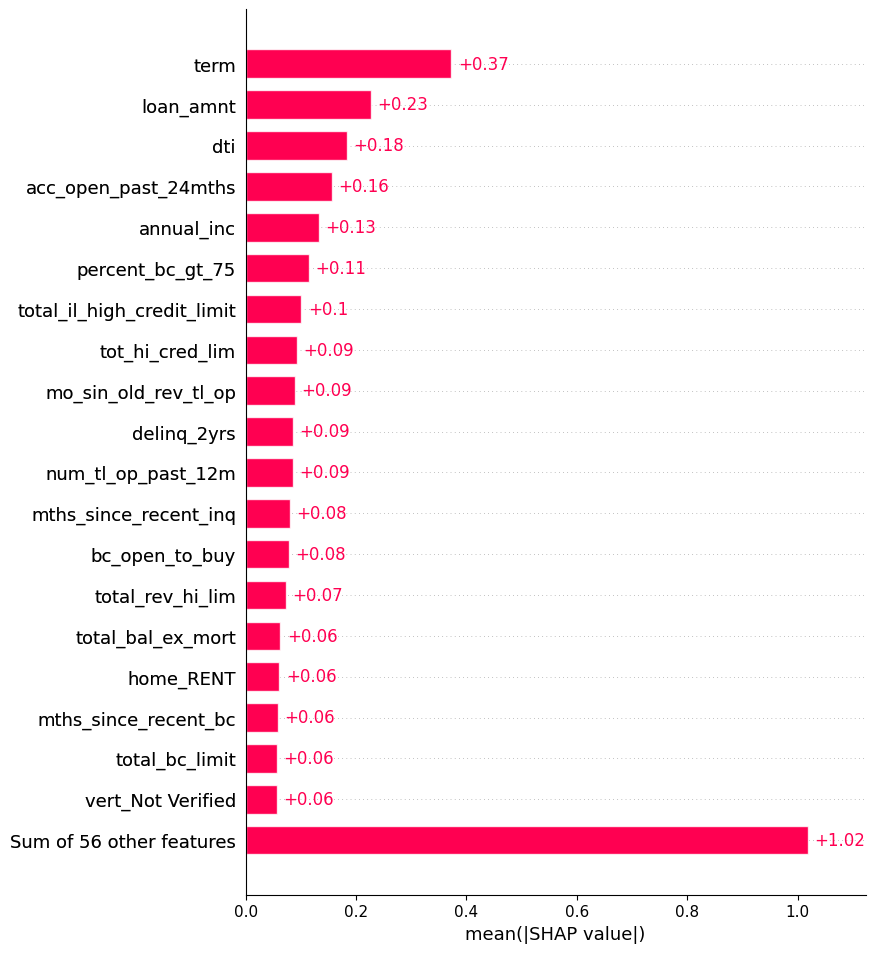

In [22]:
import shap

# Analiza istotnosci cech za pomoca wartosci SHAP
explainer = shap.TreeExplainer(best_model)
X_test_sample = X_test.sample(2000, random_state=42)
shap_values = explainer(X_test_sample)

plt.figure(figsize=(10, 6))
shap.plots.bar(shap_values, max_display=20)


In [23]:
# Weryfikacja stabilnosci modelu XGBoost (porownanie AUC na zbiorze treningowym i testowym)
best_model = random_search.best_estimator_

y_proba_train = best_model.predict_proba(X_train)[:, 1]
auc_train = roc_auc_score(y_train, y_proba_train)

y_proba_test = best_model.predict_proba(X_test)[:, 1]
auc_test = roc_auc_score(y_test, y_proba_test)

print(f"AUC na treningu: {auc_train:.4f}")
print(f"AUC na teście:   {auc_test:.4f}")
print(f"Różnica (Luka):  {auc_train - auc_test:.4f}")


AUC na treningu: 0.7458
AUC na teście:   0.7102
Różnica (Luka):  0.0356


In [24]:
# Model 2: Drzewo decyzyjne (Decision Tree) z optymalizacja RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier

X_search = pd.concat([X_train, X_val])
y_search = pd.concat([y_train, y_val])

split_fold = np.concatenate([
    np.full(len(X_train), -1),
    np.full(len(X_val), 0)
])
pds = PredefinedSplit(split_fold)

param_grid_tree = {
    'max_depth': [3, 5, 8, 10],
    'min_samples_split': [2, 10, 50, 100],
    'min_samples_leaf': [1, 5, 20, 50],
    'criterion': ['gini', 'entropy'],
    'class_weight': ['balanced', None]
}

dt_clf = DecisionTreeClassifier(random_state=42)

tree_search = RandomizedSearchCV(
    estimator=dt_clf,
    param_distributions=param_grid_tree,
    n_iter=15,
    scoring='roc_auc',
    cv=pds,
    verbose=2,
    n_jobs=-1
)

print("Optymalizacja drzewa decyzyjnego...")
tree_search.fit(X_search, y_search)

best_tree = tree_search.best_estimator_
y_proba_tree = best_tree.predict_proba(X_test)[:, 1]

print("\n" + "="*35)
print(f"Najlepsze parametry drzewa: {tree_search.best_params_}")
print(f"AUC Drzewa na teście: {roc_auc_score(y_test, y_proba_tree):.5f}")

y_pred_tree = (y_proba_tree >= 0.2).astype(int)
print(f"Macierz pomyłek (p=0.2):\n{confusion_matrix(y_test, y_pred_tree)}")
print("="*35)


Optymalizacja drzewa decyzyjnego...
Fitting 1 folds for each of 15 candidates, totalling 15 fits


In [25]:
# Weryfikacja przeuczenia (overfittingu) dla Drzewa Decyzyjnego
final_tree = tree_search.best_estimator_

y_proba_train_tree = final_tree.predict_proba(X_train)[:, 1]
auc_train_tree = roc_auc_score(y_train, y_proba_train_tree)

y_proba_test_tree = final_tree.predict_proba(X_test)[:, 1]
auc_test_tree = roc_auc_score(y_test, y_proba_test_tree)

print("\n" + "="*35)
print("TEST OVERFITTINGU (Decision Tree)")
print(f"AUC na treningu: {auc_train_tree:.5f}")
print(f"AUC na teście:   {auc_test_tree:.5f}")
print(f"Różnica (Luka):  {auc_train_tree - auc_test_tree:.5f}")
print("="*35)



TEST OVERFITTINGU (Decision Tree)
AUC na treningu: 0.72678
AUC na teście:   0.65226
Różnica (Luka):  0.07451
WNIOSEK: Lekki overfitting. Warto rozważyć zmniejszenie 'max_depth'.


In [26]:
# Model 3: Las Losowy (Random Forest) z optymalizacja RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

X_search = pd.concat([X_train, X_val])
y_search = pd.concat([y_train, y_val])

split_fold = np.concatenate([
    np.full(len(X_train), -1),
    np.full(len(X_val), 0)
])
pds = PredefinedSplit(split_fold)

param_grid_rf = {
    'n_estimators': [300],
    'max_depth': [6, 8, 10],
    'min_samples_leaf': [100, 200],
    'max_features': ['sqrt'],
    'class_weight': ['balanced'],
    'bootstrap': [True]
}

rf_clf = RandomForestClassifier(random_state=42, n_jobs=-1)

rf_search = RandomizedSearchCV(
    estimator=rf_clf,
    param_distributions=param_grid_rf,
    n_iter=10,
    scoring='roc_auc',
    cv=pds,
    verbose=2
)

print("Optymalizacja Lasu Losowego (Random Forest)...")
rf_search.fit(X_search, y_search)

best_rf = rf_search.best_estimator_
y_proba_rf = best_rf.predict_proba(X_test)[:, 1]

print("\n" + "="*35)
print(f"Najlepsze parametry RF: {rf_search.best_params_}")
print(f"AUC Random Forest na teście: {roc_auc_score(y_test, y_proba_rf):.5f}")

y_pred_rf = (y_proba_rf >= 0.2).astype(int)
print(f"Macierz pomyłek (p=0.2):\n{confusion_matrix(y_test, y_pred_rf)}")
print("="*35)


Optymalizacja Lasu Losowego (Random Forest)...
Fitting 1 folds for each of 6 candidates, totalling 6 fits


[CV] END bootstrap=True, class_weight=balanced, max_depth=6, max_features=sqrt, min_samples_leaf=100, n_estimators=300; total time= 1.1min
[CV] END bootstrap=True, class_weight=balanced, max_depth=6, max_features=sqrt, min_samples_leaf=200, n_estimators=300; total time= 1.1min
[CV] END bootstrap=True, class_weight=balanced, max_depth=8, max_features=sqrt, min_samples_leaf=100, n_estimators=300; total time= 1.3min
[CV] END bootstrap=True, class_weight=balanced, max_depth=8, max_features=sqrt, min_samples_leaf=200, n_estimators=300; total time= 1.3min
[CV] END bootstrap=True, class_weight=balanced, max_depth=10, max_features=sqrt, min_samples_leaf=100, n_estimators=300; total time= 1.6min
[CV] END bootstrap=True, class_weight=balanced, max_depth=10, max_features=sqrt, min_samples_leaf=200, n_estimators=300; total time= 1.5min

Najlepsze parametry RF: {'n_estimators': 300, 'min_samples_leaf': 200, 'max_features': 'sqrt', 'max_depth': 10, 'class_weight': 'balanced', 'bootstrap': True}
AUC 

In [27]:
# Weryfikacja przeuczenia (overfittingu) dla Lasu Losowego
final_rf = rf_search.best_estimator_

y_proba_train = final_rf.predict_proba(X_train)[:, 1]
auc_train = roc_auc_score(y_train, y_proba_train)

y_proba_test = final_rf.predict_proba(X_test)[:, 1]
auc_test = roc_auc_score(y_test, y_proba_test)

print("\n" + "="*35)
print("ANALIZA PRZEUCZENIA (Random Forest)")
print(f"AUC na treningu: {auc_train:.5f}")
print(f"AUC na teście:   {auc_test:.5f}")
print(f"Różnica (Luka):  {auc_train - auc_test:.5f}")
print("="*35)



ANALIZA PRZEUCZENIA (Random Forest)
AUC na treningu: 0.72240
AUC na teście:   0.68290
Różnica (Luka):  0.03950


In [28]:
# Model 4: Ekonometryczny model regresji logistycznej (Logit MLE - statsmodels)
import statsmodels.api as sm
from sklearn.metrics import classification_report, accuracy_score

X_train_logit = pd.concat([X_train, X_val])
y_train_logit = pd.concat([y_train, y_val])

# Usuniecie kategorii referencyjnych w celu unikniecia wspolliniowosci doskonalej
ref_cols = ['home_MORTGAGE', 'purpose_debt_consolidation', 'vert_Not Verified']
X_train_logit = X_train_logit.drop(columns=ref_cols, errors='ignore')
X_test_logit = X_test.drop(columns=ref_cols, errors='ignore')

X_train_logit = sm.add_constant(X_train_logit)
X_test_logit = sm.add_constant(X_test_logit)

print("Trwa dopasowywanie modelu Logit...")
logit_model = sm.Logit(y_train_logit, X_train_logit)
result = logit_model.fit(maxiter=100)

print(result.summary())

y_proba_logit = result.predict(X_test_logit)
p_star = 0.2
y_pred_logit = (y_proba_logit >= p_star).astype(int)

auc_score = roc_auc_score(y_test, y_proba_logit)
print("\n" + "="*35)
print(f"AUC-ROC na teście: {auc_score:.5f}")
print(f"Macierz pomyłek (próg p={p_star}):\n{confusion_matrix(y_test, y_pred_logit)}")
print("="*35)

y_proba_train = result.predict(X_train_logit)
auc_train = roc_auc_score(y_train_logit, y_proba_train)

print(f"AUC na treningu: {auc_train:.5f}")
print(f"Różnica (Luka):  {auc_train - auc_score:.5f}")

print(f"\n--- RAPORT KLASYFIKACJI DLA p = {p_star} ---")
print(classification_report(y_test, y_pred_logit, target_names=['Rzetelny (0)', 'Dłużnik (1)']))

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_logit).ravel()
accuracy = accuracy_score(y_test, y_pred_logit)
recall = tp / (tp + fn)
precision = tp / (tp + fp)
specificity = tn / (tn + fp)
f1 = 2 * (precision * recall) / (precision + recall)

print("\n" + "="*50)
print("METRYKI KLASYFIKACJI (p=0.2):")
print(f"1. Dokładność (Accuracy):  {accuracy:.2%}")
print(f"2. Czułość (Recall):        {recall:.2%}")
print(f"3. Swoistość (Specificity): {specificity:.2%}")
print(f"4. Precyzja (Precision):    {precision:.2%}")
print(f"5. Współczynnik F1:         {f1:.4f}")
print("="*50)


Trwa dopasowywanie modelu Logit (to może chwilę potrwać)...
         Current function value: 0.454897
         Iterations: 100


                           Logit Regression Results                           
Dep. Variable:                 target   No. Observations:               988226
Model:                          Logit   Df Residuals:                   988153
Method:                           MLE   Df Model:                           72
Date:                śr., 18 mar 2026   Pseudo R-squ.:                 0.09145
Time:                        16:19:57   Log-Likelihood:            -4.4954e+05
converged:                      False   LL-Null:                   -4.9479e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const                         -2.5059      0.046    -54.151      0.000      -2.597      -2.415
loan_amnt                   2.285e-05   4.33e-07     52.787      0.000     2.2e-05 

In [29]:
# Eksport tabeli parametrow modelu Logit do pliku Excel
summary_df = pd.read_html(result.summary().tables[1].as_html(), header=0, index_col=0)[0]
summary_df.to_excel("wyniki_logit_tabela.xlsx")


In [30]:
# Zapis pelnego raportu modelu Logit do pliku tekstowego i Excel
with open("pelny_raport_logit.txt", "w") as f:
    f.write(result.summary().as_text())

summary_text = result.summary().as_text()
df_text = pd.DataFrame([summary_text], columns=['Pelny_Raport_Logit'])
df_text.to_excel("raport_logit_do_archiwum.xlsx", index=False)
